# 04.1 · q-transfer eval results — load & analyze a run

Parses a `scripts/diff/q_transfer_eval.py` run: every config folder under `results/diff/q_transfer/<model>/` has `results.json` (per-instance RAW artifacts + eval verdicts) and `meta.json` (config + summary rates). This notebook flattens all instances into one table and breaks the three evals — **causal** (oracle), **readout shift** (oracle), **gaze** (rule-based) — down across the datatype / naming / language axes.

In [1]:
import sys, json
from pathlib import Path
sys.path.append("../..")
import numpy as np, pandas as pd
from IPython.display import display
from src.utils import env_utils

MODEL_SHORT = "Qwen2.5-Coder-32B-Instruct"        # <- the run to analyze
RUN_DIR = Path(env_utils.DEFAULT_RESULTS_DIR) / "diff" / "q_transfer" / MODEL_SHORT
assert RUN_DIR.exists(), f"no run at {RUN_DIR} — run scripts/diff/q_transfer_eval.py first"
config_dirs = sorted(d for d in RUN_DIR.iterdir() if d.is_dir() and (d / "results.json").exists())
print(f"run: {RUN_DIR}\n{len(config_dirs)} config folders:")
for d in config_dirs: print("  ", d.name)

run: /disk/u/arnab/Codes/Projects/goals/results/diff/q_transfer/Qwen2.5-Coder-32B-Instruct
1 config folders:
   list_str__natural__python-python


## Flatten all instances into one table

In [2]:
def _g(d, *ks):
    for k in ks: d = (d or {}).get(k) if isinstance(d, dict) else None
    return d
rows = []
for d in config_dirs:
    for r in json.loads((d / "results.json").read_text()):
        rows.append(dict(
            config=d.name, datatype=r["datatype"], naming=r["naming"],
            lang=f'{r["src_lang"]}->{r["dst_lang"]}',
            expected_next=r["expected_next"], dst_next=r["dst_next"],
            causal_triggered=_g(r, "causal", "triggered"), causal_label=_g(r, "causal", "label"),
            readout_valid=_g(r, "readout", "valid"), readout_shifted=_g(r, "readout", "shifted"),
            ro_source=_g(r, "readout", "source"), ro_dest=_g(r, "readout", "dest"),
            ro_patched=_g(r, "readout", "patched"),
            gaze_shifted=_g(r, "gaze", "shifted"), gaze_margin=_g(r, "gaze", "margin"),
            expected_next_desc=r["expected_next_desc"], dst_next_desc=r["dst_next_desc"],
            gen_patched=r["raw"].get("gen_patched", ""),
            ro_src_txt=r["raw"].get("ro_src", ""), ro_dst_txt=r["raw"].get("ro_dst", ""),
            ro_pat_txt=r["raw"].get("ro_patched", ""),
        ))
df = pd.DataFrame(rows)
# numeric copies of the boolean verdicts (True->1, False->0, missing->NaN) for group means
METRICS = ["causal_triggered", "readout_valid", "readout_shifted", "gaze_shifted"]
for c in METRICS:
    df[c + "_f"] = df[c].map({True: 1.0, False: 0.0})
MF = [c + "_f" for c in METRICS]
print(f"{len(df)} instances across {df.config.nunique()} configs")
df.head()

4 instances across 1 configs


,config,datatype,naming,lang,expected_next,dst_next,causal_triggered,causal_label,readout_valid,readout_shifted,...,expected_next_desc,dst_next_desc,gen_patched,ro_src_txt,ro_dst_txt,ro_pat_txt,causal_triggered_f,readout_valid_f,readout_shifted_f,gaze_shifted_f
0,list_str__natural__python-python,list[str],natural,python->python,count_long,total_length,True,both,True,True,...,the number of words longer than five characters,the total number of characters across all words,total_long_words = sum(1 for w in words if le...,I'm checking if the length of the string is gr...,Counting characters.,I'm checking if the length of the string is gr...,1.0,1.0,1.0,1.0
1,list_str__natural__python-python,list[str],natural,python->python,count_capitalized,total_length,True,both,True,True,...,the number of capitalized words,the total number of characters across all words,total_chars = sum(1 for w in words if w.isalp...,Checking if the variable is uppercase.,Counting characters.,Identifying the current line and checking if i...,1.0,1.0,1.0,1.0
2,list_str__natural__python-python,list[str],natural,python->python,distinct_count,total_length,True,both,True,True,...,the number of distinct words,the total number of characters across all words,total_chars = len(set(words))\n distinct_w...,I'm counting unique elements in a list.,Counting characters.,Identifying unique elements by converting the ...,1.0,1.0,1.0,1.0
3,list_str__natural__python-python,list[str],natural,python->python,count_capitalized,count_long,True,src,True,True,...,the number of capitalized words,the number of words longer than five characters,long_words = sum(1 for w in words if w.isuppe...,Checking if the variable is uppercase.,I'm checking if the length of the string is gr...,I'm checking if the variable is uppercase.,1.0,1.0,1.0,1.0


## Overall rates

In [3]:
def _rate(s):
    s = s.dropna()
    return f"{s.mean():.1%}  (n={len(s)})" if len(s) else "— (n=0)"
valid = df[df.readout_valid == True]
print("OVERALL")
print("  causal triggered      :", _rate(df.causal_triggered_f))
print("  readout valid         :", _rate(df.readout_valid_f))
print("  readout shifted (all) :", _rate(df.readout_shifted_f))
print("  readout shifted|valid :", _rate(valid.readout_shifted_f), " <- the meaningful one")
print("  gaze shifted          :", _rate(df.gaze_shifted_f))

OVERALL
  causal triggered      : 100.0%  (n=4)
  readout valid         : 100.0%  (n=4)
  readout shifted (all) : 100.0%  (n=4)
  readout shifted|valid : 100.0%  (n=4)  <- the meaningful one
  gaze shifted          : 100.0%  (n=4)


## Breakdown by each axis

In [4]:
for axis in ["datatype", "naming", "lang"]:
    g = df.groupby(axis)[MF].mean().rename(columns=lambda c: c[:-2])
    g["n"] = df.groupby(axis).size()
    print(f"=== by {axis} ===")
    display(g.style.format({c: "{:.1%}" for c in METRICS}))

=== by datatype ===


,causal_triggered,readout_valid,readout_shifted,gaze_shifted,n
datatype,,,,,
list[str],100.0%,100.0%,100.0%,100.0%,4


=== by naming ===


,causal_triggered,readout_valid,readout_shifted,gaze_shifted,n
naming,,,,,
natural,100.0%,100.0%,100.0%,100.0%,4


=== by lang ===


,causal_triggered,readout_valid,readout_shifted,gaze_shifted,n
lang,,,,,
python->python,100.0%,100.0%,100.0%,100.0%,4


## Readout shift among VALID cases, by axis

The clean readouts must land as expected (source→SRC, dest→DST) for the case to be analyzable; restrict to those, then ask how often the patched readout moved to the SRC target.

In [5]:
v = df[df.readout_valid == True]
if len(v):
    for axis in ["datatype", "naming", "lang"]:
        g = v.groupby(axis)["readout_shifted_f"].agg(["mean", "size"]).rename(
            columns={"mean": "shift|valid", "size": "n_valid"})
        print(f"=== {axis} ==="); display(g.style.format({"shift|valid": "{:.1%}"}))
    print("patched-readout label distribution (valid cases):")
    display(v.ro_patched.value_counts(dropna=False))
else:
    print("no valid readout cases (oracle may have been skipped with --no-oracle)")

=== datatype ===


,shift|valid,n_valid
datatype,,
list[str],100.0%,4


=== naming ===


,shift|valid,n_valid
naming,,
natural,100.0%,4


=== lang ===


,shift|valid,n_valid
lang,,
python->python,100.0%,4


patched-readout label distribution (valid cases):


ro_patched
src    4
Name: count, dtype: int64

## Agreement between the three signals

Do causal success, readout shift, and gaze shift co-occur on the same instances?

In [6]:
sig = df.dropna(subset=["causal_triggered", "readout_shifted", "gaze_shifted"])
if len(sig):
    print(f"n={len(sig)} instances with all three signals")
    print("causal vs readout_shifted:")
    display(pd.crosstab(sig.causal_triggered, sig.readout_shifted))
    print("causal vs gaze_shifted:")
    display(pd.crosstab(sig.causal_triggered, sig.gaze_shifted))
else:
    print("need oracle + gaze verdicts on the same instances")

n=4 instances with all three signals
causal vs readout_shifted:


readout_shifted,True
causal_triggered,
True,4


causal vs gaze_shifted:


gaze_shifted,True
causal_triggered,
True,4


## Gaze margin distribution

`margin = mean Δattn on SRC-target span − mean Δattn on DST-target span` (patched − clean). >0 ⇒ gaze moved toward the SRC goal.

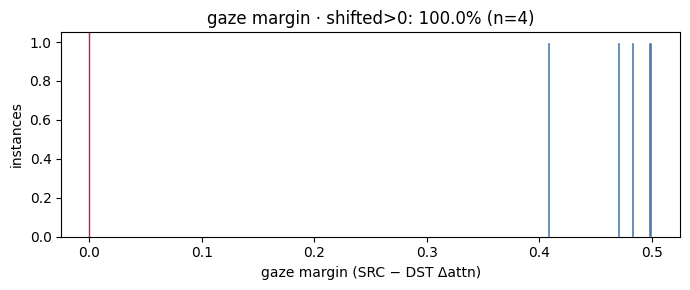

In [7]:
import matplotlib.pyplot as plt
m = df.gaze_margin.dropna().astype(float)
if len(m):
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(m, bins=30, color="#4c78a8", edgecolor="white")
    ax.axvline(0, color="crimson", lw=1)
    ax.set_xlabel("gaze margin (SRC − DST Δattn)"); ax.set_ylabel("instances")
    ax.set_title(f"gaze margin · shifted>{0}: {(m > 0).mean():.1%} (n={len(m)})")
    plt.tight_layout(); plt.show()
else:
    print("no gaze margins")

## Qualitative — inspect a few instances

Eyeball the patched generation + the three readouts against the SRC/DST targets.

In [8]:
def show_instance(row):
    print(f"[{row.config}]  expected(SRC)={row.expected_next!r} ({row.expected_next_desc})")
    print(f"                 dst_next   ={row.dst_next!r} ({row.dst_next_desc})")
    print(f"  causal={row.causal_label} triggered={row.causal_triggered} | "
          f"readout {row.ro_source}->{row.ro_dest}->{row.ro_patched} "
          f"(valid={row.readout_valid}, shifted={row.readout_shifted}) | gaze_shift={row.gaze_shifted}")
    print("  readout src :", row.ro_src_txt)
    print("  readout dst :", row.ro_dst_txt)
    print("  readout pat :", row.ro_pat_txt)
    print("  patched gen :\n    " + row.gen_patched.replace("\n", "\n    "))
    print("-" * 90)

# a few triggered and a few not (fall back to head() if oracle skipped)
trig = df[df.causal_triggered == True].head(2)
notrig = df[df.causal_triggered == False].head(2)
sample = pd.concat([trig, notrig]) if len(trig) + len(notrig) else df.head(3)
for _, row in sample.iterrows():
    show_instance(row)

[list_str__natural__python-python]  expected(SRC)='count_long' (the number of words longer than five characters)
                 dst_next   ='total_length' (the total number of characters across all words)
  causal=both triggered=True | readout src->dst->src (valid=True, shifted=True) | gaze_shift=True
  readout src : I'm checking if the length of the string is greater than 5.
  readout dst : Counting characters.
  readout pat : I'm checking if the length of the string is greater than 5.
  patched gen :
     total_long_words = sum(1 for w in words if len(w) > 5)
        total_capitalized = sum(1 for w in words if w.istitle())
        total_chars = sum(len(w) for w in words)
        distinct_words = len(set(words))
        return has_palindrome, total_chars, total_long_words, total_capitalized, distinct_words
    </code>
------------------------------------------------------------------------------------------
[list_str__natural__python-python]  expected(SRC)='count_capitalized' (the n

## Config-level summary (from each `meta.json`)

In [9]:
metas = [json.loads((d / "meta.json").read_text()) for d in config_dirs if (d / "meta.json").exists()]
mdf = pd.DataFrame(metas)
cols = ["datatype", "naming", "src_lang", "dst_lang", "n_instances",
        "causal_trigger_rate", "readout_valid_rate", "readout_shift_rate_valid", "gaze_shift_rate"]
display(mdf[[c for c in cols if c in mdf.columns]])

,datatype,naming,src_lang,dst_lang,n_instances,causal_trigger_rate,readout_valid_rate,readout_shift_rate_valid,gaze_shift_rate
0,list[str],natural,python,python,4,1.0,1.0,1.0,1.0
